In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from matplotlib.colors import LogNorm
from TDECalculator import TDECalculator

plt.style.use("plot_style.mplstyle")
plt.rc('text', usetex=True)

ModuleNotFoundError: No module named 'TDECalculator'

## Call the TDECalculator class ##

In [ ]:
# orbit denotes the type of trajectory, 'nwtn' for Newtonian and 'rel' for relativistic
# MBH is the black hole masses, in units of solar masses
# Rp is the pericenter distance, in units of G MBH
# a is the black hole spin, in units of MBH
# E is orbital energy of the star's center of mass
# Q is the Carter constant of the star's center of mass
# N is the number of steps in the time integration
calc_pro = TDECalculator('RGB3Msun_z0p0300', orbit='rel', MBH=1e6, Rp=41, a=0.2, E=1.0, Q=0.0, N=5000)        # prograde trajectory
#calc_retro = TDECalculator('RGB3Msun_z0p0142_logR0p5', orbit='rel', MBH=1e6, Rp=66.52, a=-0.2, E=1.0, Q=0.0, N=3500)     # retrograde trajectory
#calc_sch = TDECalculator('RGB3Msun_z0p0142_logR0p5', orbit='rel', MBH=1e6, Rp=66.52, a=0.0, E=1.0, Q=0.0, N=3500)         # schwartzschild trajectory
#calc_nwtn = TDECalculator('RGB3Msun_z0p0142_logR0p5', orbit='nwtn', MBH=1e6, Rp=66.52, a=0.0, E=1.0, Q=0.0, N=3500)      # newtonian trajectory

In [30]:
print("Rp =", calc_pro.Rp)
print("beta =", calc_pro.Rtidal / calc_pro.Rp)
print("U =", calc_pro.U)
print("gamma =", calc_pro.gamma)

threshold = calc_pro.gamma * (
    calc_pro.U * calc_pro.mass_ratio**2 / calc_pro.Rstar
)

print("threshold =", threshold)
print("max TidalEnergy =", np.max(calc_pro.TidalEnergy))
print("max energy / threshold =", np.max(calc_pro.TidalEnergy) / threshold)

print("Rtidal =", calc_pro.Rtidal)
print("Rp     =", calc_pro.Rp)
print("beta   =", calc_pro.Rtidal / calc_pro.Rp)
print("Mstar =", calc_pro.Mstar)
print("Rstar =", calc_pro.Rstar)
print("Rtidal =", calc_pro.Rtidal)
print("Rp =", calc_pro.Rp)
print("beta =", calc_pro.Rtidal / calc_pro.Rp)

Rp = 33.25
beta = 10.001069207750723
U = 3.019030690771907
gamma = 0.7388084722628752
threshold = 4.1856893889507316e-12
max TidalEnergy = 8.919656455025694e-12
max energy / threshold = 2.1309886200757178
Rtidal = 332.53555115771155
Rp     = 33.25
beta   = 10.001069207750723
Mstar = 3.00001489242313
Rstar = 4.796000493672836
Rtidal = 332.53555115771155
Rp = 33.25
beta = 10.001069207750723


Number of modes: 431
q shape: (3, 3, 1000, 431)
Green-function factor: 0.0002312386606082958

Quadrupole reconstruction check:
max absolute difference  = 2.541098841762901e-21
max relative difference  = 4.3580896727268087e-16

Energy reconstruction check:
max absolute difference  = 1.7577588016751838e-24
max relative difference  = 2.5479362983410228e-15

Total-energy peak:
time   = 357.7703397421951
energy = 6.898754897521071e-10

LARGEST MODE CONTRIBUTIONS AT TOTAL-ENERGY PEAK
    n_pg              E_mode          Fraction      Abs fraction
--------------------------------------------------------------------------------
    -364      2.48069868e-10    3.59586436e-01    3.59586436e-01
    -278      7.51612281e-11    1.08948976e-01    1.08948976e-01
    -363      4.92772533e-11    7.14291986e-02    7.14291986e-02
    -365      4.88094657e-11    7.07511231e-02    7.07511231e-02
    -225      3.94332647e-11    5.71599734e-02    5.71599734e-02
    -279      3.21143799e-11    4.65509797e-02

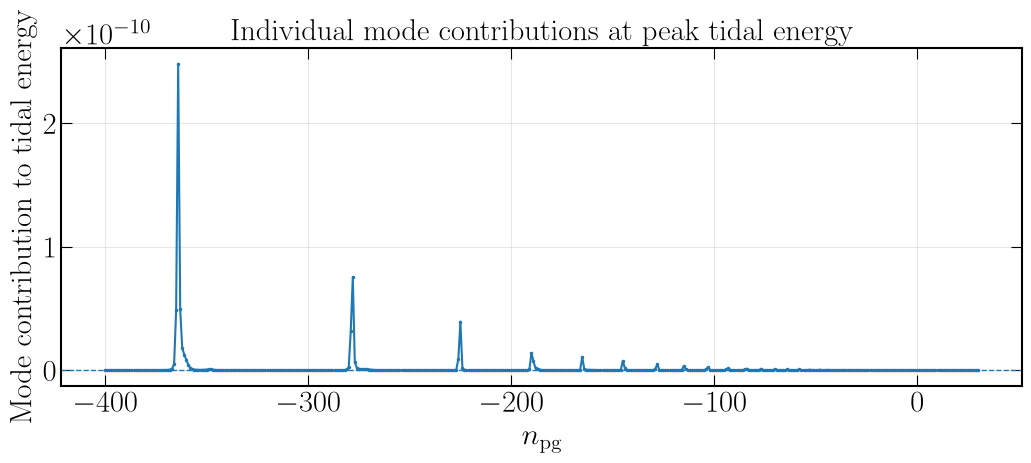

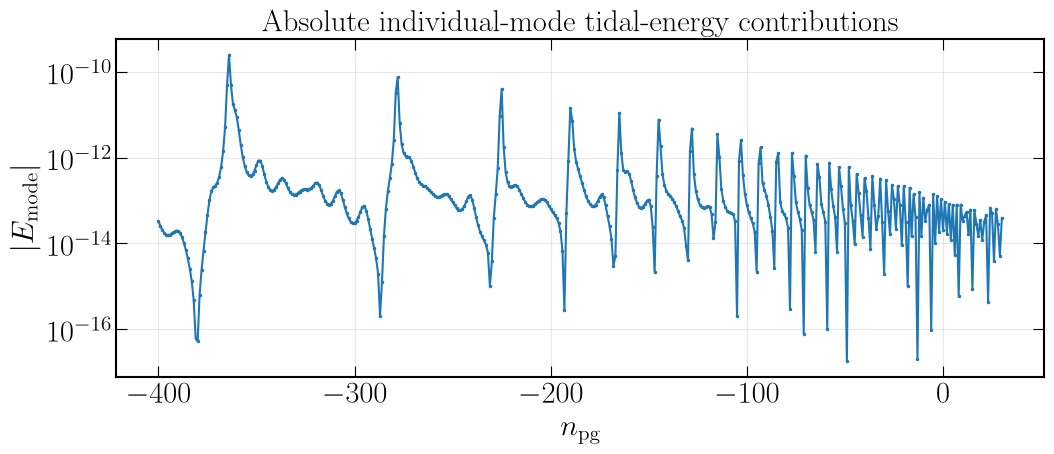

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# EXACT INDIVIDUAL-MODE TIDAL-ENERGY DECOMPOSITION
# ============================================================

t = calc_pro.t
E = calc_pro.E
dEdt = calc_pro.dEdt

q = calc_pro.q
omega = np.asarray(calc_pro.omega)

n_pg = np.asarray(calc_pro.summary["n_pg"], dtype=int)

n_modes = len(n_pg)
N = len(t)

print("Number of modes:", n_modes)
print("q shape:", q.shape)


# ============================================================
# The actual prefactor used by Gret_Q in TDECalculator.py
# ============================================================

factor = (
    (16 * np.pi / 15)
    * calc_pro.mass_ratio
    * calc_pro.Rstar**2
)

print("Green-function factor:", factor)


# ============================================================
# Convert q_j -> Q_j
#
# q_j uses:
#     overlap_xi[j] * sin(omega_j dt) / omega_j
#
# Q_j uses:
#     factor * overlap_Q[j] * sin(omega_j dt) / omega_j
#
# Therefore:
#
#     Q_j = q_j * factor * overlap_Q[j] / overlap_xi[j]
# ============================================================

overlap_Q = np.asarray(calc_pro.overlap_Q)
overlap_xi = np.asarray(calc_pro.overlap_xi)

Q_mode = np.zeros_like(q)

for j in range(n_modes):

    if overlap_xi[j] != 0:

        conversion = (
            factor
            * overlap_Q[j]
            / overlap_xi[j]
        )

        Q_mode[:, :, :, j] = q[:, :, :, j] * conversion


# ============================================================
# Verify that summing the individual Q_j reproduces Q_all
# ============================================================

Q_reconstructed = np.sum(Q_mode, axis=3)

Q_difference = np.max(
    np.abs(Q_reconstructed - calc_pro.Q_all)
)

Q_relative_difference = (
    Q_difference
    / np.max(np.abs(calc_pro.Q_all))
)

print("\nQuadrupole reconstruction check:")
print("max absolute difference  =", Q_difference)
print("max relative difference  =", Q_relative_difference)


# ============================================================
# Calculate the tidal energy contribution of EACH mode
# using the EXACT SAME formula as _compute_tidal_energy()
# ============================================================

mode_energy = np.zeros((n_modes, N))

for j in range(n_modes):

    Qj = Q_mode[:, :, :, j]

    # Power from this individual mode
    power_j = (
        Qj[0, 0] * dEdt[0, 0]
      + Qj[1, 1] * dEdt[1, 1]
      + Qj[2, 2] * dEdt[2, 2]
      + 2 * Qj[0, 1] * dEdt[0, 1]
    )

    # Same cumulative integral used in TDECalculator
    cumulative_j = (
        0.5
        * np.concatenate(
            (
                [0.0],
                np.cumsum(
                    0.5
                    * (power_j[1:] + power_j[:-1])
                    * np.diff(t)
                )
            )
        )
    )

    # Same instantaneous potential term
    instant_j = 0.5 * (
        Qj[0, 0] * E[0, 0]
      + Qj[1, 1] * E[1, 1]
      + Qj[2, 2] * E[2, 2]
      + 2 * Qj[0, 1] * E[0, 1]
    )

    mode_energy[j] = cumulative_j - instant_j


# ============================================================
# EXACT reconstruction of total tidal energy
# ============================================================

reconstructed_energy = np.sum(mode_energy, axis=0)

energy_difference = np.max(
    np.abs(
        reconstructed_energy
        - calc_pro.TidalEnergy
    )
)

energy_relative_difference = (
    energy_difference
    / np.max(np.abs(calc_pro.TidalEnergy))
)

print("\nEnergy reconstruction check:")
print("max absolute difference  =", energy_difference)
print("max relative difference  =", energy_relative_difference)


# ============================================================
# Find total-energy peak
# ============================================================

peak_index = np.argmax(calc_pro.TidalEnergy)

peak_time = t[peak_index]
peak_energy = calc_pro.TidalEnergy[peak_index]

print("\nTotal-energy peak:")
print("time   =", peak_time)
print("energy =", peak_energy)


# ============================================================
# Individual mode contributions at the peak
# ============================================================

E_peak = mode_energy[:, peak_index]

order = np.argsort(np.abs(E_peak))[::-1]

print("\n" + "=" * 80)
print("LARGEST MODE CONTRIBUTIONS AT TOTAL-ENERGY PEAK")
print("=" * 80)

print(
    f"{'n_pg':>8}"
    f"{'E_mode':>20}"
    f"{'Fraction':>18}"
    f"{'Abs fraction':>18}"
)

print("-" * 80)

for j in order[:50]:

    fraction = E_peak[j] / peak_energy

    print(
        f"{n_pg[j]:>8d}"
        f"{E_peak[j]:>20.8e}"
        f"{fraction:>18.8e}"
        f"{abs(fraction):>18.8e}"
    )


# ============================================================
# Separate g / f / p modes
# ============================================================

g_mask = n_pg < 0
f_mask = n_pg == 0
p_mask = n_pg > 0

E_g = np.sum(mode_energy[g_mask], axis=0)
E_f = np.sum(mode_energy[f_mask], axis=0)
E_p = np.sum(mode_energy[p_mask], axis=0)

print("\n" + "=" * 80)
print("MODE-CLASS CONTRIBUTIONS AT TOTAL-ENERGY PEAK")
print("=" * 80)

print("g-mode energy =", E_g[peak_index])
print("f-mode energy =", E_f[peak_index])
print("p-mode energy =", E_p[peak_index])
print("total         =", reconstructed_energy[peak_index])

print("\nFractions:")
print("g-mode fraction =", E_g[peak_index] / peak_energy)
print("f-mode fraction =", E_f[peak_index] / peak_energy)
print("p-mode fraction =", E_p[peak_index] / peak_energy)


# ============================================================
# Plot individual mode contributions
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(
    n_pg,
    E_peak,
    ".-",
    markersize=3
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel(r"$n_{\rm pg}$")
plt.ylabel("Mode contribution to tidal energy")
plt.title(
    "Individual mode contributions at peak tidal energy"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# Plot absolute contributions
# ============================================================

plt.figure(figsize=(11, 5))

plt.semilogy(
    n_pg,
    np.maximum(np.abs(E_peak), 1e-30),
    ".-",
    markersize=3
)

plt.xlabel(r"$n_{\rm pg}$")
plt.ylabel(r"$|E_{\rm mode}|$")
plt.title(
    "Absolute individual-mode tidal-energy contributions"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Plot the deformed star's equator density ##

In [3]:
def density_plots(calc):
    # Use the “equator_sample” method to get POS and dMass.
    # Here we use equator_sample to get an equatorial slice:
    equator_sample = calc.equator_sample()
    POS    = equator_sample['POS']        # shape (n_r, 1, n_phi, 3)
    dMass  = equator_sample['dMass']      # shape (n_r, n_phi)

    # flatten x, y, and mass
    x_pos   = POS[...,0].flatten()
    y_pos   = POS[...,1].flatten()
    mass_flat = dMass.flatten()

    # define histogram bin edges
    nbins   = 300
    x_edges = np.linspace(-2, 2, nbins+1)
    y_edges = np.linspace(-3, 3, nbins+1)

    # build 2D mass histogram
    mass_hist, x_edges, y_edges = np.histogram2d(
        x_pos, y_pos,
        bins=[x_edges, y_edges],
        weights=mass_flat
    )

    # convert to surface density
    dx    = x_edges[1] - x_edges[0]
    dy    = y_edges[1] - y_edges[0]
    area  = dx*dy
    density2D = mass_hist / area
    # add tiny non‑constant offset for stable contours
    Xc, Yc = np.meshgrid(
        0.5*(x_edges[:-1]+x_edges[1:]),
        0.5*(y_edges[:-1]+y_edges[1:])
    )
    density2D += 1e-12*(Xc + Yc)

    # prepare interpolation onto a finer grid
    points = np.column_stack((Xc.flatten(), Yc.flatten()))
    values = density2D.T.flatten()
    xi     = np.linspace(Xc.min(), Xc.max(), nbins)
    yi     = np.linspace(Yc.min(), Yc.max(), nbins)
    XI, YI = np.meshgrid(xi, yi)
    dens_interp = griddata(points, values, (XI, YI), method='linear')
    # normalize for plotting
    dens_interp += dens_interp.max()*1e-8
    center_idx_x = tuple(dim // 2 for dim in XI.shape)[0]
    center_idx_y = tuple(dim // 2 for dim in YI.shape)[0]
    Sigma_c = dens_interp[center_idx_x, center_idx_y]
    dens_interp /= Sigma_c

    # — plot! —
    plt.figure(figsize=(8,8))
    levels = np.logspace(
        np.log10(dens_interp[dens_interp>0].min()),
        np.log10(dens_interp.max()),
        100
    )
    cf = plt.contourf(
        XI, YI, dens_interp,
        levels=levels,
        cmap='viridis',
        norm=LogNorm()
    )

    # arrow pointing “to BH”
    phi0 = calc.Psi_TDE if calc.orbit == "rel" else calc.Phi_TDE
    plt.arrow(-1.5, 2.25, -0.3*np.cos(phi0), -0.3*np.sin(phi0),
            linewidth=2, head_width=0.1, head_length=0.1, color='white')
    plt.text(-1.5-0.3*np.cos(phi0)+0.1,
            2.25-0.3*np.sin(phi0)+0.1,
            'to BH', color='white', fontsize=14)

    # annotate mass and β
    beta = calc.Rtidal / calc.Rp
    plt.text(1.3, 2.5,  fr'${calc.star_name[4:-4]}\,M_\odot$',
            color='white', fontsize=20)
    plt.text(-1.7, -2.5, fr'$\beta={beta:.2f}$',
            color='white', fontsize=20)

    plt.axis('scaled')
    plt.axis('off')
    plt.colorbar(cf, label='$\\rho/\\rho_c$', ticks=[1e-8, 1e-6, 1e-4, 1e-2, 1])
    plt.show()

### Prograde ###

python(16461) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


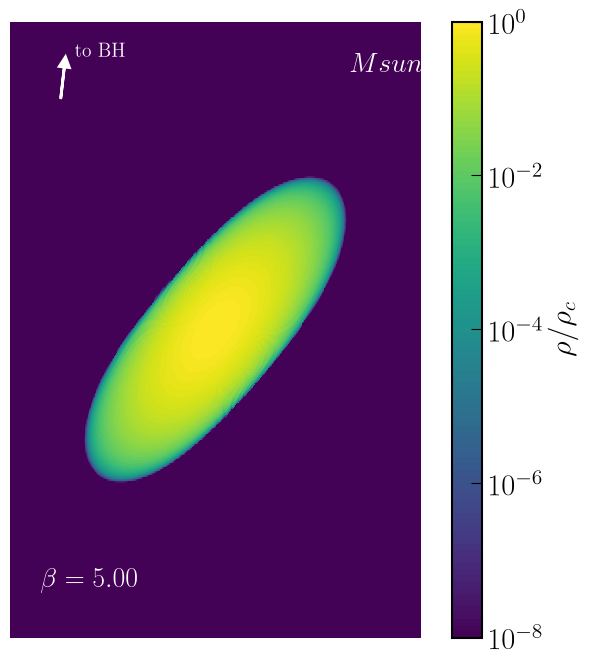

In [4]:
density_plots(calc_pro)

### Retrograde ###

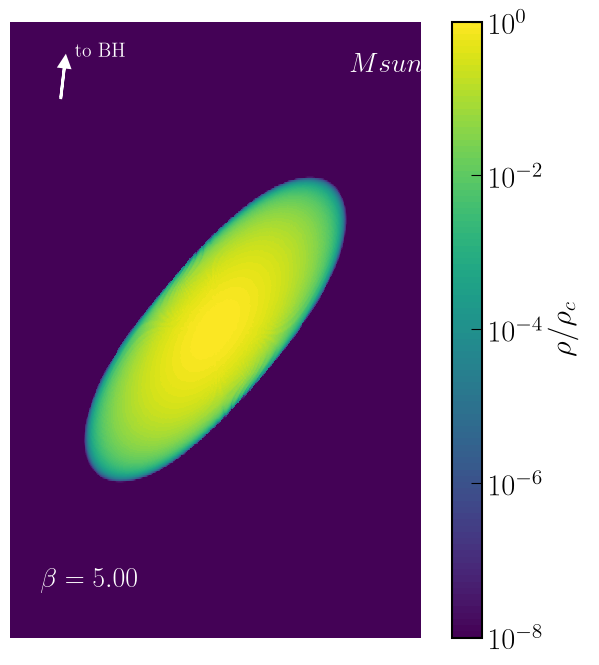

In [5]:
density_plots(calc_retro)

### Schwartzschild ###

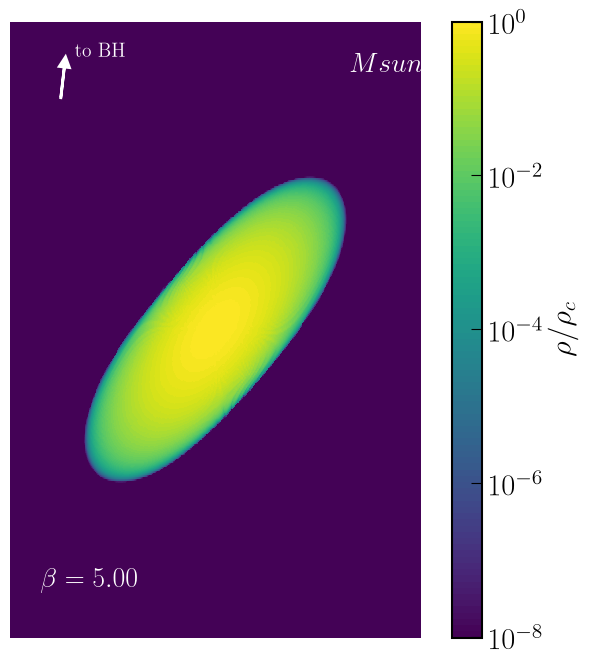

In [6]:
density_plots(calc_sch)

### Newtonian ###

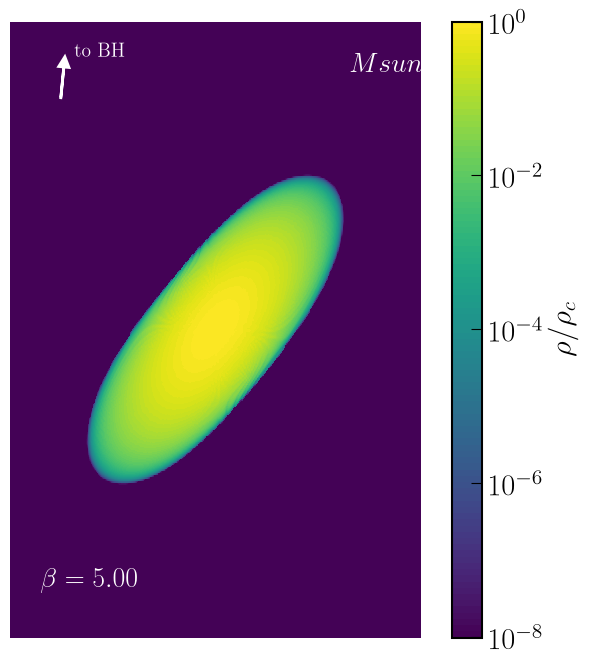

In [7]:
density_plots(calc_nwtn)

## Compute $dM/dE$ and $dM/dT$ ##

see FallbackGen_example.ipynb

Rtidal = 332.57013522145553
Rp     = 66.52
beta   = 4.999551040611178
Mstar = 3.00001489242313
Rstar = 4.796499283008929
Rtidal = 332.57013522145553
Rp = 66.52
beta = 4.999551040611178
Rstar = 4.796499283008929
